<a href="https://colab.research.google.com/github/hyo-yeon-lee/MCNB-Probability-and-Statistics/blob/main/lecture06_linreg1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Linear regression

In this practical, we'll cove simple linear regression (i.e., regression with a single predictor).

We'll look at two packages: ```scikit-learn``` and ```statsmodels```, as they both have their strengths and weaknesses.

##Exercise 1: Scikit-learn

First, we'll see how to use ```scikit-learn```. Here is some pseudocode that illustrates how to run linear regression with this library, using the [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) class.

```
# Fit a linear regression model
model = LinearRegression()
model.fit(x, y)

# Get slope, intercept, and R^2
slope = model.coef_[0][0]
intercept = model.intercept_[0]
r2 = model.score(x, y)

# Get predictions
preds = model.predict(x)
```
>Notes:
1. ```X``` should have shape ```(n_samples, 1)``` (and not juste ```(n_samples,)```). This is because when we do multiple regression (i.e., with several predictors), we'll want to have them in shape ```(n_samples, n_predictors)```. If you have data ```x``` with shape ```(n_samples,)``` and want to transform it to shape ```(n_samples, 1)```, you can use ```x = np.reshape(x, [-1, 1])```, or ```x = np.expand_dims(x, axis=-1)``` or ```x = x[:, None]```. All of these are ways to add an empty second dimension, as required here.
2. ```y``` should have shape also have shape ```(n_samples, 1)```. This is because we might have cases when we are predicting several targets, in which case we'll have shape ```(n_samples, n_targets)``` (unlike for X, I don't think this is an absolute requirement in sklearn, but it is good practice).

In the cell below, you'll find some synthetic data.
1. Fit linear regression.
2. Print the coefficients, and the R2 score.
3. Make a figure showing a scatterplot of the individual datapoints, overlayed with a line plot showing the regression line.



X shape:  (100, 1)  Y shape:  (100, 1)
slope:  [2.40804535]  intercept:  [0.43019232]
r-squared:  0.9402877892004072


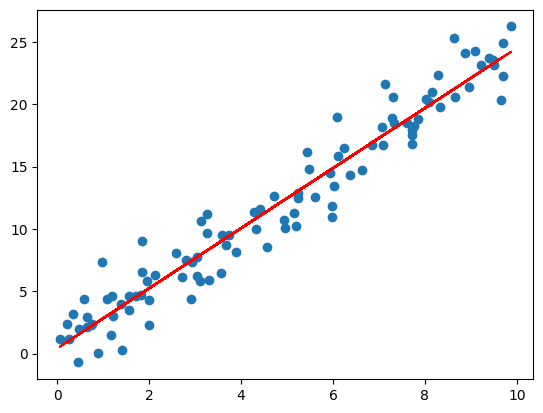

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd

# Generate synthetic data
np.random.seed(42)
x = np.random.rand(100, 1) * 10  # Predictor
y = 2.5 * x + np.random.randn(100, 1) * 2  # Response with noise

# DELETE THE FOLLOWING LINE AND WRITE YOUR CODE BELOW
# Print the shapes of x and y to make sure they are as expected
print("X shape: ", np.shape(x), " Y shape: ", np.shape(y))

# Fit a linear regression model
model = LinearRegression(fit_intercept=True)
model.fit(x, y)

# Print slope, intercept, and R^2
print("slope: ", model.coef_[0], " intercept: ", model.intercept_)
y_pred = model.predict(x)
r_sqd = r2_score(y, y_pred)
print("r-squared: ", r_sqd)

# Plot data and regression line
plt.plot(figsize=(8, 5))
plt.plot(x, y_pred, color='r')
plt.scatter(x, y)
plt.show()
plt.close()


Now, we will make a train/test split. Do the following steps:

1. Shuffle the x and y data *keeping the match between x and y*, as we covered previously.
2. Split the shuffled arrays: use the first 80% indices as x_train and y_train, and the last 20% as y_test.
3. Fit the regression on x_train and y_train.
4. Print the R2 score evaluated on y_test.
5. Make the same plot as above, but separately for the train and test data. Does your model generalize to the test set (it should).

-0.2770629630588881
slope:  [-0.15694329] intercept:  [13.23323105]


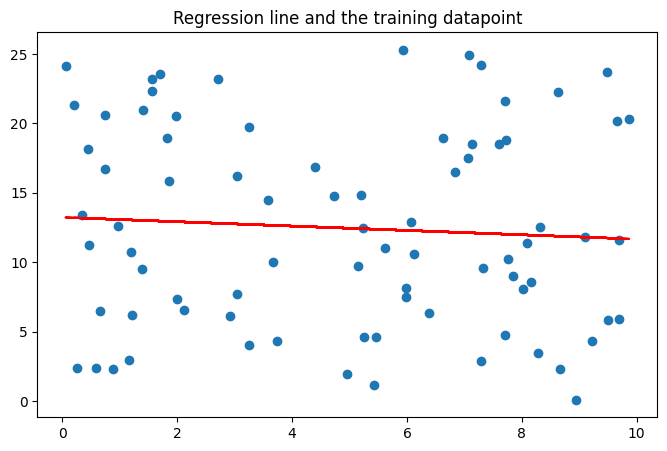

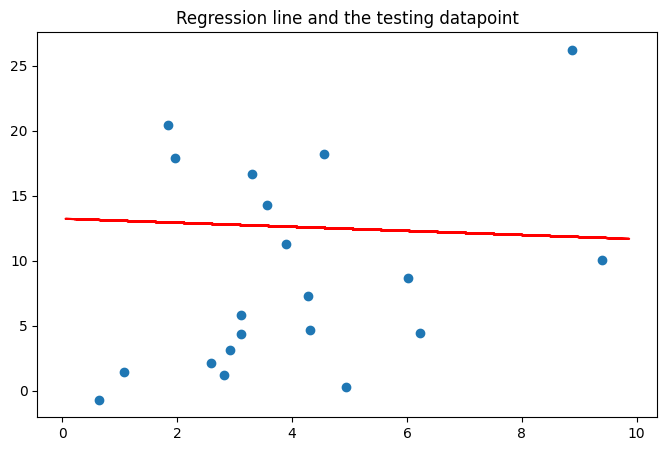

In [58]:
# DELETE THE FOLLOWING LINE AND WRITE YOUR CODE BELOW
from sklearn.model_selection import train_test_split

# Shuffle and split into train/test sets
train_x, test_x, train_y, test_y = train_test_split(x, y, test_size=0.2, shuffle=True)

# Fit the regression model on training data
model_2 = LinearRegression()
model_2.fit(train_x, train_y)

# Make predictions on test data
y_pred_2 = model_2.predict(test_x)

# Calculate testR2
r_sqd_2 = r2_score(test_y, y_pred_2)
print(r_sqd_2)

slope = model_2.coef_[0]
intercept = model_2.intercept_

print("slope: ", slope, "intercept: ", intercept)

reg_y = x * slope + intercept

# Visualize regression line and training datapoint
plt.figure(figsize=(8, 5))
plt.plot(x, reg_y, color='r')
plt.scatter(train_x, train_y)
plt.title("Regression line and the training datapoint")
plt.show()
plt.close()


# Visualize regression line and testing datapoint
plt.figure(figsize=(8, 5))
plt.plot(x, reg_y, color='r')
plt.scatter(test_x, test_y)
plt.title("Regression line and the testing datapoint")
plt.show()
plt.close()



To run cross-validation, you can use [cross_val_score](https://scikit-learn.org/dev/modules/generated/sklearn.model_selection.cross_val_score.html). Check the online documentation or any kind of online help you want for how it works.

Print the 5-fold cross-validated R2 score of linear regression on our synthetic data.

In [61]:
from sklearn.model_selection import cross_val_score

# DELETE THE FOLLOWING LINE AND WRITE YOUR CODE BELOW
# Perform 5-fold cross-validation and print results

score = cross_val_score(model_2, x, y, cv=5)
print("cross validation score: ", score.mean())

cross validation score:  -0.07776201197206141


>*BONUS:* In case you want to go a bit deeper, here is code plotting the score, regression line and test data for all cross-validation folds. There is no inbuilt function to do this in sklearn, so I did it by hand. You can look at this score to see cross-validation explicitly coded.

Cross-Validation R^2 Scores: [0.9545718935323327, 0.9587075728537054, 0.8400143193492101, 0.9496810816220194, 0.9270536967945654]
Mean R^2: 0.93
Standard Deviation of R^2: 0.04


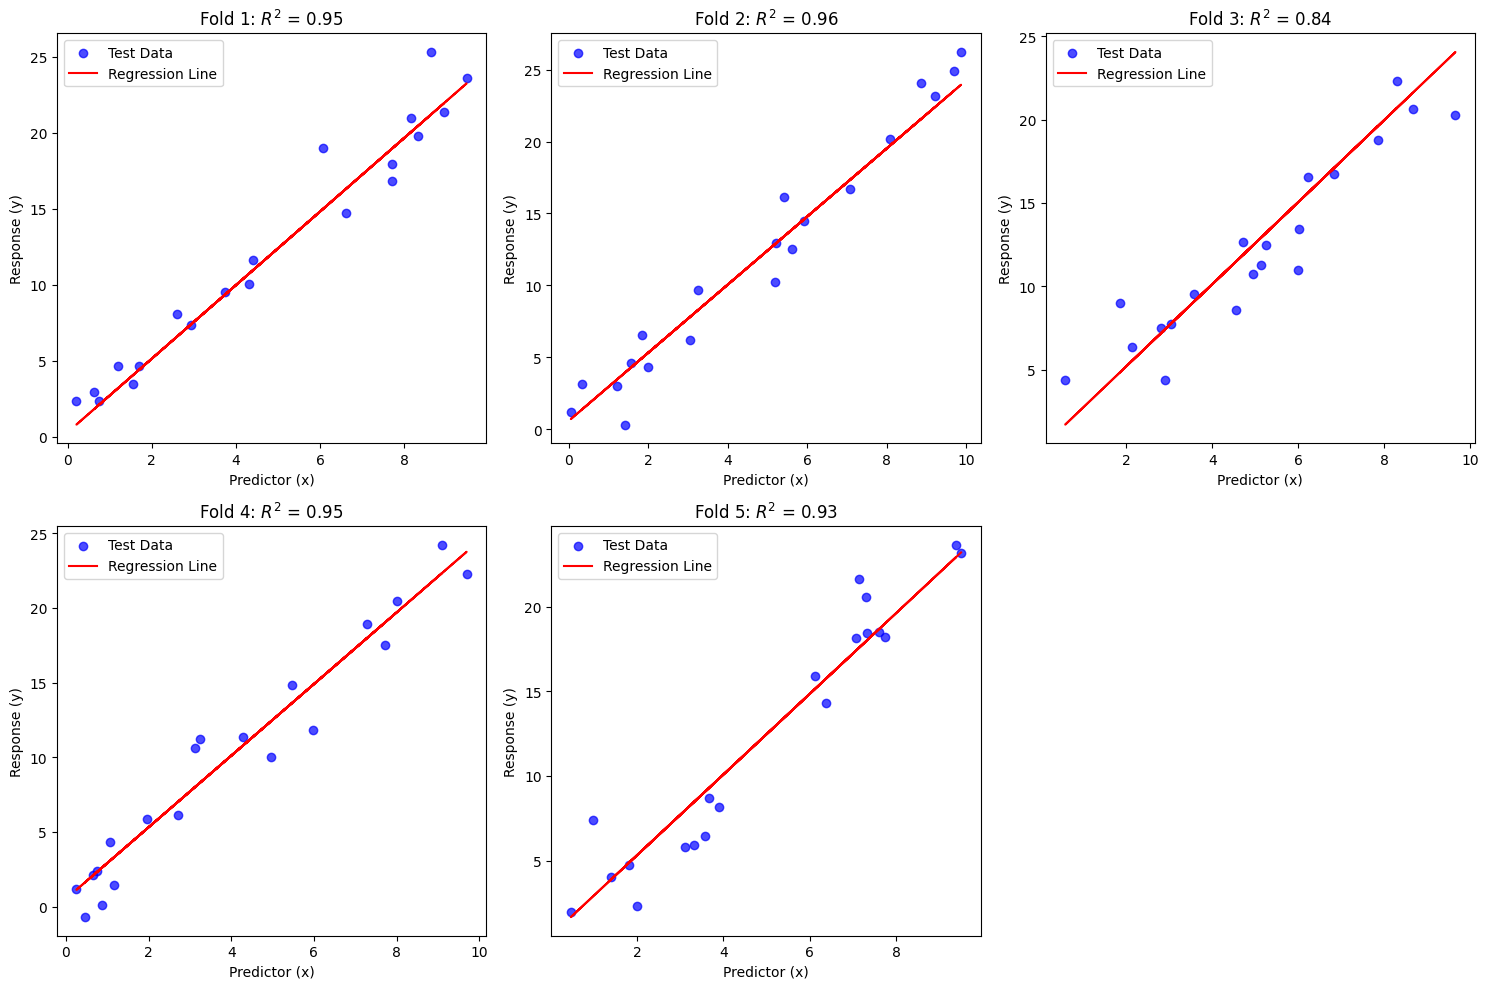

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Synthetic dataset
np.random.seed(42)
x = np.random.rand(100, 1) * 10  # Predictor
y = 2.5 * x + np.random.randn(100, 1) * 2  # Response with noise

# Set up KFold for cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
model = LinearRegression()

# Initialize list to store scores
r2_scores = []

# Create figure for plots
plt.figure(figsize=(15, 10))

# Perform 5-fold cross-validation
for fold_idx, (train_idx, test_idx) in enumerate(kf.split(x)):
    # Split the data into training and testing sets
    x_train, x_test = x[train_idx], x[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Fit the model on the training data
    model.fit(x_train, y_train)

    # Predict on the test data
    y_pred = model.predict(x_test)

    # Calculate R^2 for the test data
    r2 = r2_score(y_test, y_pred)
    r2_scores.append(r2)

    # Plot the test data and regression line
    plt.subplot(2, 3, fold_idx + 1)  # Arrange plots in a 2x3 grid
    plt.scatter(x_test, y_test, color="blue", label="Test Data", alpha=0.7)
    plt.plot(x_test, y_pred, color="red", label="Regression Line")
    plt.title(f"Fold {fold_idx + 1}: $R^2$ = {r2:.2f}")
    plt.xlabel("Predictor (x)")
    plt.ylabel("Response (y)")
    plt.legend()

# Print summary statistics
print(f"Cross-Validation R^2 Scores: {r2_scores}")
print(f"Mean R^2: {np.mean(r2_scores):.2f}")
print(f"Standard Deviation of R^2: {np.std(r2_scores):.2f}")

# Show the plots
plt.tight_layout()
plt.show()


#Exercise 2: statsmodels
The ```statsmodels``` package has the advantage of returning a lot of information about the fitted linear regression. Run the code below, and find R2, the p-value for the t-statistic and the p-value for the F-statistic. Is there a significant linear relashionship in this data?

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.928
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     102.7
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           7.67e-06
Time:                        10:32:41   Log-Likelihood:                -27.548
No. Observations:                  10   AIC:                             59.10
Df Residuals:                       8   BIC:                             59.70
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         42.4000      2.905     14.596      0.0

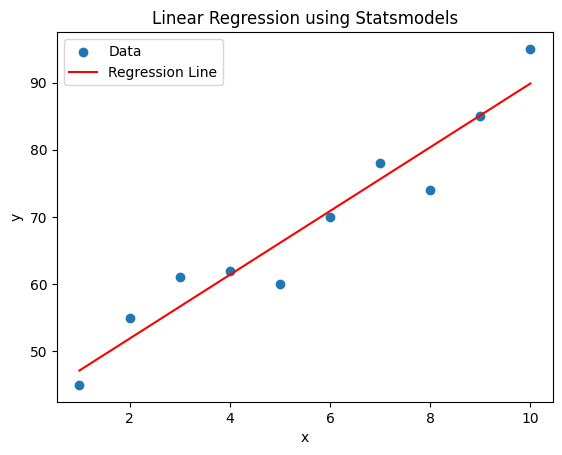

In [63]:
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt

# Example dataset
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
y = np.array([45, 55, 61, 62, 60, 70, 78, 74, 85, 95])

# Fit the model
x_with_const = sm.add_constant(x)  # Add a constant term for the intercept
model = sm.OLS(y, x_with_const).fit()  # Note the order: y first, then x_with_const

# Print the summary
print(model.summary())

# Visualize regression line
plt.scatter(x, y, label="Data")
plt.plot(x, model.predict(x_with_const), color="red", label="Regression Line")  # Use x_with_const
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Linear Regression using Statsmodels")
plt.show()
